# Real-World Evidence on OMOP CDM
**Cohort analytics on MIMIC-IV demo data (work in progress)**

This notebook explores the MIMIC-IV demo dataset (100 ICU patients) converted to the OMOP Common Data Model, using SQL (DuckDB) and Python.

**Data source:** MIMIC-IV demo data in the OMOP CDM, v0.9 (PhysioNet, Open Database License). Data are not included in this repository: download them from PhysioNet and place the `1_omop_data_csv/` folder inside `data/`.

## 1. Setup

In [25]:
# Libraries
import duckdb
import glob
import os
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# Path to the OMOP CSV files
DATA = "../data/1_omop_data_csv"

## 2. Load OMOP tables as DuckDB views
Each CSV file becomes a named view, so tables can be queried directly with SQL (e.g. `FROM person`).

In [7]:
# Create one view per CSV file
for path in glob.glob(f"{DATA}/*.csv"):
    name = os.path.basename(path).replace(".csv", "")
    duckdb.sql(f'''CREATE OR REPLACE VIEW "{name}" AS SELECT * FROM read_csv_auto('{path}')''')

# List all tables
duckdb.sql("SHOW TABLES")

nameVARCHAR
2b_concept
2b_concept_relationship
2b_vocabulary
attribute_definition
care_site
cdm_source
cohort
cohort_attribute
cohort_definition
condition_era


## 3. Number of patients

In [8]:
# Count patients in the person table
duckdb.sql("SELECT COUNT(*) AS n_patients FROM person")

n_patientsBIGINT
100


## 4. Explore the person table
Note: MIMIC-IV shifts dates into the future (e.g. birth years after 2100) to protect patient identity. A `concept_id` of 0 means the source value could not be mapped to a standard concept.

In [9]:
# First 5 rows
duckdb.sql("SELECT * FROM person LIMIT 5")

person_idBIGINT,gender_concept_idBIGINT,year_of_birthBIGINT,month_of_birthVARCHAR,day_of_birthVARCHAR,birth_datetimeVARCHAR,race_concept_idBIGINT,ethnicity_concept_idBIGINT,location_idVARCHAR,provider_idVARCHAR,care_site_idVARCHAR,person_source_valueBIGINT,gender_source_valueVARCHAR,gender_source_concept_idBIGINT,race_source_valueVARCHAR,race_source_concept_idBIGINT,ethnicity_source_valueVARCHAR,ethnicity_source_concept_idBIGINT
3589912774911670296,8507,2095,NULL,NULL,NULL,0,38003563,NULL,NULL,NULL,10009628,M,0,NULL,0,HISPANIC/LATINO,2000001408
-3210373572193940939,8507,2079,NULL,NULL,NULL,0,38003563,NULL,NULL,NULL,10011398,M,0,NULL,0,HISPANIC/LATINO,2000001408
-775517641933593374,8507,2149,NULL,NULL,NULL,8516,0,NULL,NULL,NULL,10004235,M,0,BLACK/AFRICAN AMERICAN,2000001406,NULL,0
-2575767131279873665,8507,2050,NULL,NULL,NULL,8516,0,NULL,NULL,NULL,10024043,M,0,BLACK/AFRICAN AMERICAN,2000001406,NULL,0
-8970844422700220177,8507,2114,NULL,NULL,NULL,8527,0,NULL,NULL,NULL,10038933,M,0,WHITE,2000001404,NULL,0


## 5. Patients by sex: standard concept vs. source value

In [10]:
# Patients by sex
duckdb.sql("""
SELECT gender_concept_id, gender_source_value, COUNT(*) AS n
FROM person
GROUP BY gender_concept_id, gender_source_value
""")

gender_concept_idBIGINT,gender_source_valueVARCHAR,nBIGINT
8507,M,57
8532,F,43


## 6. Size of the measurement table

In [12]:
# Total measurements and average per patient
duckdb.sql("""
SELECT COUNT(*) AS n_measurements,
       COUNT(*) / 100 AS avg_per_patient
FROM measurement
""")

n_measurementsBIGINT,avg_per_patientDOUBLE
338550,3385.5


## 7. Visits per patient (LEFT JOIN)

In [13]:
# Number of visits per patient, keeping all patients
duckdb.sql("""
SELECT p.person_id,
       p.gender_source_value AS sex,
       COUNT(v.visit_occurrence_id) AS n_visits
FROM person AS p
LEFT JOIN visit_occurrence AS v
       ON p.person_id = v.person_id
GROUP BY p.person_id, p.gender_source_value
ORDER BY n_visits DESC
LIMIT 10
""")

person_idBIGINT,sexVARCHAR,n_visitsBIGINT
-6225647829918357531,F,102
4783904755296699562,M,92
7155255168997124770,M,71
1741351032930224901,F,42
7918537411740862407,F,38
4985579811051920670,F,31
7131048714591189903,M,28
3129727379702505063,F,28
-626229666378242477,M,26
1258460361496302149,F,26


## 8. Visit types
Total visits per standard `visit_concept_id`. Concept names will be added once the full OMOP vocabulary (Athena) is loaded.

In [15]:
# How many visits of each type?
duckdb.sql("""
SELECT visit_concept_id,
       COUNT(*) AS n
FROM visit_occurrence
GROUP BY visit_concept_id
ORDER BY n DESC
""")

visit_concept_idBIGINT,nBIGINT
38004207,582
8870,119
581385,82
262,38
8883,18
9201,13


## 9. Age at first visit (JOIN + aggregation)

In [16]:
# Age at each patient's first visit
duckdb.sql("""
SELECT p.person_id,
       p.year_of_birth,
       MIN(YEAR(v.visit_start_date)) AS first_visit_year,
       MIN(YEAR(v.visit_start_date)) - p.year_of_birth AS age_at_first_visit
FROM person AS p
JOIN visit_occurrence AS v
  ON p.person_id = v.person_id
GROUP BY p.person_id, p.year_of_birth
ORDER BY age_at_first_visit DESC
LIMIT 10
""")

person_idBIGINT,year_of_birthBIGINT,first_visit_yearBIGINT,age_at_first_visitBIGINT
7427037643503998178,2084,2175,91
1740609625029317924,2093,2184,91
-1115201667562228350,2062,2153,91
-8659404739579738033,2066,2155,89
5734523979606454056,2069,2157,88
1194579079287927665,2089,2176,87
3665089643642765251,2085,2172,87
-8205283012979532608,2103,2189,86
-1095016967997700156,2041,2125,84
-2312013739856114142,2030,2114,84


## 10. Age summary using a CTE

In [17]:
# Step 1 (CTE): first visit per patient. Step 2: age statistics
duckdb.sql("""
WITH first_visit AS (
    SELECT person_id,
           MIN(visit_start_date) AS first_visit_date
    FROM visit_occurrence
    GROUP BY person_id
)
SELECT COUNT(*) AS n_patients,
       ROUND(AVG(YEAR(f.first_visit_date) - p.year_of_birth), 1) AS mean_age,
       MIN(YEAR(f.first_visit_date) - p.year_of_birth) AS min_age,
       MAX(YEAR(f.first_visit_date) - p.year_of_birth) AS max_age
FROM first_visit AS f
JOIN person AS p
  ON f.person_id = p.person_id
""")

n_patientsBIGINT,mean_ageDOUBLE,min_ageBIGINT,max_ageBIGINT
100,61.5,21,91


## 11. Visit sequence and days since previous discharge (window functions)
Readmission within 30 days of discharge is a common real-world outcome.

In [18]:
# Number each visit per patient and compute days since previous discharge
duckdb.sql("""
SELECT person_id,
       visit_start_date,
       visit_end_date,
       ROW_NUMBER() OVER (PARTITION BY person_id ORDER BY visit_start_date) AS visit_number,
       visit_start_date - LAG(visit_end_date) OVER (PARTITION BY person_id ORDER BY visit_start_date) AS days_since_previous
FROM visit_occurrence
ORDER BY person_id, visit_number
LIMIT 20
""")

person_idBIGINT,visit_start_dateDATE,visit_end_dateDATE,visit_numberBIGINT,days_since_previousBIGINT
-9066461348710750663,2185-01-17,2185-01-22,1,NULL
-8993675534959689080,2181-09-02,2181-09-02,1,NULL
-8993675534959689080,2181-10-12,2181-10-14,2,40
-8993675534959689080,2181-10-25,2181-10-27,3,11
-8970844422700220177,2148-09-10,2148-09-23,1,NULL
-8928428202649726867,2185-06-15,2185-06-21,1,NULL
-8891617624507360381,2134-07-15,2134-07-15,1,NULL
-8891617624507360381,2134-08-29,2134-08-29,2,45
-8891617624507360381,2134-09-07,2134-09-11,3,9
-8891617624507360381,2134-09-26,2134-09-26,4,15


## 12. 30-day readmissions
A readmission is a visit starting 0–30 days after the previous discharge of the same patient.

In [20]:
# Count 30-day readmissions
duckdb.sql("""
WITH visits AS (
    SELECT person_id,
           visit_start_date - LAG(visit_end_date) OVER (PARTITION BY person_id ORDER BY visit_start_date) AS days_since_previous
    FROM visit_occurrence
)
SELECT COUNT(*) AS n_readmissions_30d,
       COUNT(DISTINCT person_id) AS n_patients_readmitted
FROM visits
WHERE days_since_previous BETWEEN 0 AND 30
""")

n_readmissions_30dBIGINT,n_patients_readmittedBIGINT
438,62


## 13. Inspect diagnosis source codes
Before defining a phenotype, check how diagnoses are coded in the source data.

In [21]:
# Most frequent diagnosis codes
duckdb.sql("""
SELECT condition_source_value, condition_concept_id, COUNT(*) AS n
FROM condition_occurrence
GROUP BY condition_source_value, condition_concept_id
ORDER BY n DESC
LIMIT 15
""")

condition_source_valueVARCHAR,condition_concept_idBIGINT,nBIGINT
SR (Sinus Rhythm),4145513,6531
AF (Atrial Fibrillation),4064452,2405
ST (Sinus Tachycardia),4140598,2302
V Paced,4092038,502
SB (Sinus Bradycardia),4138456,390
225106,433753,157
A Paced,4089488,153
4019,320128,68
1st AV (First degree AV Block),316135,66
E785,432867,57


In [22]:
# Search for respiratory failure codes (ICD-10 J96*, ICD-9 518.81 / 518.82 / 518.84)
duckdb.sql("""
SELECT condition_source_value, COUNT(*) AS n, COUNT(DISTINCT person_id) AS n_patients
FROM condition_occurrence
WHERE condition_source_value ILIKE 'J96%'
   OR condition_source_value ILIKE '5188%'
GROUP BY condition_source_value
ORDER BY n DESC
""")

condition_source_valueVARCHAR,nBIGINT,n_patientsBIGINT
51881,14,12
J9601,11,8
J9600,4,4
J9621,3,3
J9691,3,3
51889,2,2
J9610,1,1
J9622,1,1
J9690,1,1


## 14. Respiratory failure phenotype and cohort
**Phenotype (source codes):** ICD-10 `J96*` (respiratory failure) and ICD-9 `51881`, `51882`, `51884`. Code `51889` (other lung diseases) is excluded.
**Index date:** date of the first respiratory failure diagnosis. **Index visit:** the hospital visit of that diagnosis.

In [23]:
# Build the cohort: one row per patient, first respiratory failure diagnosis
duckdb.sql("""
CREATE OR REPLACE TABLE resp_cohort AS
WITH resp_dx AS (
    SELECT person_id,
           visit_occurrence_id,
           condition_start_date,
           ROW_NUMBER() OVER (PARTITION BY person_id ORDER BY condition_start_date) AS rn
    FROM condition_occurrence
    WHERE condition_source_value LIKE 'J96%'
       OR condition_source_value IN ('51881', '51882', '51884')
)
SELECT r.person_id,
       r.condition_start_date AS index_date,
       r.visit_occurrence_id AS index_visit_id,
       v.visit_start_date,
       v.visit_end_date
FROM resp_dx AS r
LEFT JOIN visit_occurrence AS v
  ON r.visit_occurrence_id = v.visit_occurrence_id
WHERE r.rn = 1
""")

# Check the cohort
duckdb.sql("""
SELECT COUNT(*) AS n_patients,
       COUNT(index_visit_id) AS n_with_index_visit
FROM resp_cohort
""")

n_patientsBIGINT,n_with_index_visitBIGINT
19,19


## 15. Analysis table: covariates and outcomes
**Covariates:** age at index, sex, number of prior visits.
**Outcomes:** length of stay of the index visit, in-hospital death, 30-day readmission after index discharge, time to death (for survival analysis).

In [24]:
# One row per patient with covariates and outcomes
duckdb.sql("""
CREATE OR REPLACE TABLE resp_analysis AS
WITH next_visit AS (
    SELECT c.person_id, MIN(v.visit_start_date) AS next_visit_date
    FROM resp_cohort AS c
    JOIN visit_occurrence AS v
      ON v.person_id = c.person_id AND v.visit_start_date > c.visit_end_date
    GROUP BY c.person_id
),
prior_visits AS (
    SELECT c.person_id, COUNT(v.visit_occurrence_id) AS n_prior_visits
    FROM resp_cohort AS c
    LEFT JOIN visit_occurrence AS v
      ON v.person_id = c.person_id AND v.visit_start_date < c.visit_start_date
    GROUP BY c.person_id
),
obs_end AS (
    SELECT person_id, MAX(observation_period_end_date) AS obs_end_date
    FROM observation_period
    GROUP BY person_id
)
SELECT c.person_id,
       c.index_date,
       YEAR(c.index_date) - p.year_of_birth AS age,
       p.gender_source_value AS sex,
       pv.n_prior_visits,
       c.visit_end_date - c.visit_start_date AS los_days,
       d.death_date,
       CASE WHEN d.death_date BETWEEN c.visit_start_date AND c.visit_end_date THEN 1 ELSE 0 END AS in_hospital_death,
       CASE WHEN nv.next_visit_date - c.visit_end_date <= 30 THEN 1 ELSE 0 END AS readmit_30d,
       COALESCE(d.death_date, o.obs_end_date) - c.index_date AS time_days,
       CASE WHEN d.death_date IS NOT NULL THEN 1 ELSE 0 END AS death_event
FROM resp_cohort AS c
JOIN person AS p        ON p.person_id = c.person_id
LEFT JOIN death AS d    ON d.person_id = c.person_id
LEFT JOIN next_visit AS nv   ON nv.person_id = c.person_id
LEFT JOIN prior_visits AS pv ON pv.person_id = c.person_id
LEFT JOIN obs_end AS o  ON o.person_id = c.person_id
""")

# Summary of outcomes
duckdb.sql("""
SELECT COUNT(*) AS n,
       ROUND(AVG(age), 1) AS mean_age,
       ROUND(MEDIAN(los_days), 1) AS median_los_days,
       SUM(in_hospital_death) AS in_hospital_deaths,
       SUM(readmit_30d) AS readmissions_30d
FROM resp_analysis
""")

nBIGINT,mean_ageDOUBLE,median_los_daysDOUBLE,in_hospital_deathsHUGEINT,readmissions_30dHUGEINT
19,63.4,9.0,8,5


## 16. Data quality: missing values
Note: a missing `death_date` is not missing data. It means the patient did not die during observation (structural missingness).

In [26]:
# Null percentage and basic statistics for every column
duckdb.sql("SUMMARIZE resp_analysis")

column_nameVARCHAR,column_typeVARCHAR,minVARCHAR,maxVARCHAR,approx_uniqueBIGINT,avgVARCHAR,stdVARCHAR,q25VARCHAR,q50VARCHAR,q75VARCHAR,countBIGINT,"null_percentageDECIMAL(9,2)"
person_id,BIGINT,-8659404739579738033,8090044958540695372,18,1.5719539875554707e+17,5.191937884098308e+18,-4241959677136274944,579254014084392320,4675976337486875648,19,0.00
index_date,DATE,2113-09-12,2186-11-12,19,2147-05-30 07:34:44.210526316,NULL,2132-04-17,2146-06-10,2170-05-23,19,0.00
age,BIGINT,28,92,17,63.36842105263158,17.82697870057187,51,67,74,19,0.00
sex,VARCHAR,F,M,2,NULL,NULL,NULL,NULL,NULL,19,0.00
n_prior_visits,BIGINT,0,91,9,8.842105263157896,20.489192701125628,1,1,8,19,0.00
los_days,BIGINT,5,34,13,12.789473684210526,9.34867160717037,5,9,16,19,0.00
death_date,DATE,2116-03-12,2186-11-17,9,2149-10-22 02:40:00,NULL,2130-08-06,2146-07-12,2175-12-22,19,52.63
in_hospital_death,INTEGER,0,1,2,0.42105263157894735,0.5072572735017881,0,0,1,19,0.00
readmit_30d,INTEGER,0,1,2,0.2631578947368421,0.45241392835886407,0,0,1,19,0.00
time_days,BIGINT,5,1460,16,217.57894736842104,382.1496675663249,11,29,316,19,0.00


## 17. Survival analysis: Kaplan-Meier
Time from index date to death. Patients who did not die are censored at the end of their observation period.

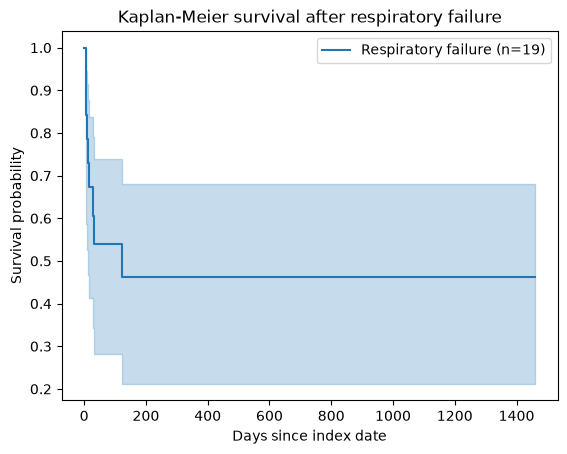

Median survival (days): 122.0


In [27]:
# Load the analysis table into pandas
df = duckdb.sql("SELECT * FROM resp_analysis WHERE time_days IS NOT NULL").df()

# Fit the Kaplan-Meier estimator
kmf = KaplanMeierFitter()
kmf.fit(durations=df["time_days"], event_observed=df["death_event"], label="Respiratory failure (n=19)")

# Plot and save the curve
os.makedirs("../figures", exist_ok=True)
ax = kmf.plot_survival_function()
ax.set_xlabel("Days since index date")
ax.set_ylabel("Survival probability")
ax.set_title("Kaplan-Meier survival after respiratory failure")
plt.savefig("../figures/km_survival.png", dpi=150, bbox_inches="tight")
plt.show()

# Median survival time (days)
print("Median survival (days):", kmf.median_survival_time_)

## 18. Limitations
- **Small sample:** 19 patients from a 100-patient demo dataset. Results are descriptive and illustrate the method; they are not clinical evidence.
- **Phenotype based on source codes:** ICD-9/ICD-10 billing codes were used instead of standard OMOP concepts, and the phenotype was not validated against chart review. Next step: map to standard SNOMED concepts with the full OMOP vocabulary (Athena).
- **Index date precision:** billing diagnoses are recorded per admission, so the index date reflects the admission rather than the exact onset of respiratory failure.
- **De-identification:** MIMIC-IV shifts dates into the future and caps ages above 89 at 91, which affects age distributions.
- **Visit definition:** short visits (emergency stays, transfers) inflate naive readmission counts. Readmission was defined as the first visit within 30 days after discharge of the index visit.
- **Data placement:** some monitoring data (e.g. cardiac rhythms) appear in `condition_occurrence`, which shows ETL choices that must be checked before analysis.
- **No adjustment for confounding:** outcomes are unadjusted; comparisons between groups would require methods such as regression or propensity scores.
- **Single centre:** MIMIC-IV comes from one US academic hospital (Beth Israel Deaconess Medical Center), which limits generalisability.